<a href="https://colab.research.google.com/github/DanDC25/Statistical-Learning-with-Python/blob/main/%5BLAB%5D_DSA211_10_Lab_Tree_Based_Methods.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Part 0: Setup and Data

This lab applies the lecture's workflow to two new datasets:

- **Boston** (Part 1): median house value in 506 Boston census tracts. A regression tree.
- **OJ** (Part 2): 1,070 orange juice purchases, Citrus Hill or Minute Maid. A classification tree.

The workflow:

1. split once,
2. tune `ccp_alpha` by CV on the training set,
3. touch the test set once to compute the generalisation error,
4. refit on all the data.

In [90]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
                                     cross_val_score)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, accuracy_score, confusion_matrix

np.random.seed(2026)

The response is `medv`, median home value in \$1,000s. The 12 predictors include `rm` (average rooms per dwelling), `lstat` (% lower-status population), `crim` (crime rate) and `dis` (distance to employment centres).

In [91]:
url = 'https://raw.githubusercontent.com/intro-stat-learning/ISLP/main/ISLP/data/Boston.csv'
boston = pd.read_csv(url)
boston.index = range(1, len(boston) + 1)

X = boston.drop(columns='medv')
y = boston['medv']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2026)

print(f'Training: {len(X_train)} tracts, test: {len(X_test)} tracts')

Training: 354 tracts, test: 152 tracts


EDA happens after the split, on the training set only.

- Two predictors, `rm` and `lstat`, carry most of the signal.
- The relationship with `rm` and `lstat` is strongly non-linear.
- Note also the cluster of tracts at exactly 50, where `medv` was capped.

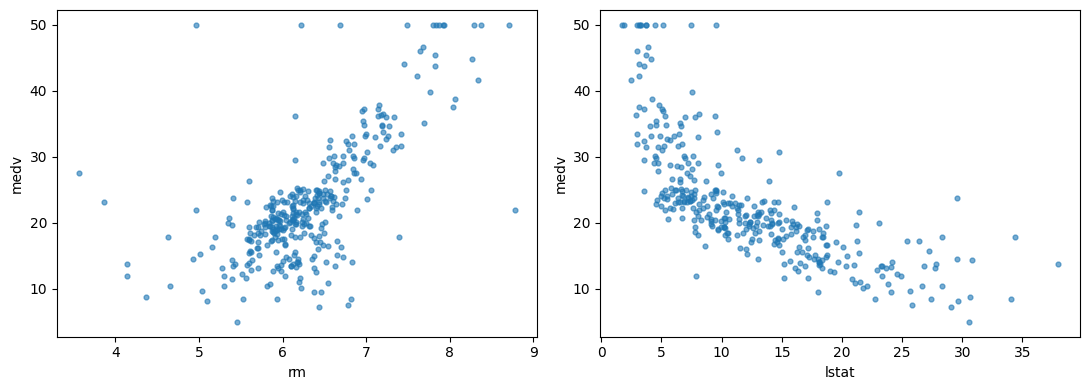

In [92]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, col in zip(ax, ['rm', 'lstat']):
    a.scatter(X_train[col], y_train, s=12, alpha=0.6)
    a.set_xlabel(col)
    a.set_ylabel('medv')
plt.tight_layout()
plt.show()

***

## Part 1: Regression Trees on Boston

### 1.1 A First Tree

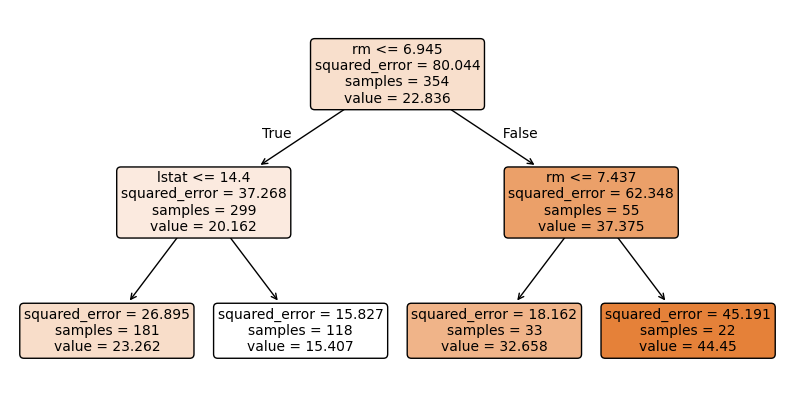

In [93]:
small_tree = DecisionTreeRegressor(max_depth=2,
                                   random_state=2026)
small_tree.fit(X_train, y_train);

fig, ax = plt.subplots(figsize=(10, 5))
plot_tree(small_tree,
          feature_names=list(X_train.columns),
          filled=True,
          rounded=True,
          fontsize=10, ax=ax)
plt.show()

❓ **Question 1.1a.** Which predictor does the tree split on first, and at what value? The right branch splits on the *same* predictor again. What does a repeated split on one predictor tell you about the shape of its relationship with `medv`?

*Your answer here:*

The tree splits using predictor 'rm' first, specifically whether obsverations have the 'rm' value of ≤ 6.945.

It appears that the right branch splits on the same predictor 'rm' again. This implies that rm's effect is not a single step - it requires two. Perhaps the relationship between rm and medv is exponential where medv increases at an increasing rate in rm.

### Exercise 1.1: Training error vs CV error

For `max_depth` in `[2, 3, None]`, fit a tree on the training set and record its number of leaves, its training MSE and its 5-fold CV MSE (use the `cv` object below). Show all three in one table.

In [94]:
cv = KFold(n_splits=5,
           shuffle=True,
           random_state=2026)

In [95]:
### YOUR CODE HERE
# For each depth in [2, 3, None]:
#   1. Fit DecisionTreeRegressor(max_depth=depth, random_state=2026) on the training set
#   2. Record get_n_leaves(), the training MSE, and the CV MSE
#      (CV MSE = -cross_val_score(..., cv=cv, scoring='neg_mean_squared_error').mean())
# Put the results in one DataFrame, one row per depth

results_list = []

cv = KFold(n_splits=5,
shuffle=True,
random_state=2026)

for label, depth in [('Depth-2 tree', 2), ('Depth-3 tree', 3), ('Fully grown tree', None)]:
  model = DecisionTreeRegressor(max_depth=depth,random_state=2026)
  model.fit(X_train, y_train)
  mse = mean_squared_error(y_train, model.predict(X_train))
  CV_MSE = -cross_val_score(model, X_train, y_train, cv=cv, scoring='neg_mean_squared_error').mean()
  results_list.append({
        'Model': label,
        'Number of leaves': model.get_n_leaves(),
        'Training MSE': mse,
        'CV MSE': CV_MSE})

results = pd.DataFrame(results_list).set_index('Model')
print(results)


                  Number of leaves  Training MSE     CV MSE
Model                                                      
Depth-2 tree                     4     23.528523  25.542087
Depth-3 tree                     8     13.505906  19.141682
Fully grown tree               337      0.000000  15.260365


❓ **Question 1.1b.** Rank the three trees by training MSE, then by CV MSE. Do the two rankings agree? In the lecture, the fully grown Hitters tree had a higher CV MSE than the depth-2 tree. Does the same happen on Boston? What is different about the two datasets?

*Your answer here:*

Yes, the two rankings do agree where Training MSE and CV MSE follows in a descending order: Depth-2 tree, Depth-3 tree, Fully grown tree.

Compared to the orders of CV MSE of the 3 trees in the Hitters dataset, the order on the Boston dataset differs where Boston's fully grown tree has a lower CV MSE than the depth-2 tree.

Boston is a larger dataset - more observations, - which allows for larger training set so trees would have sufficient amount of data on each leaves.

***

### 1.2 Pruning by Cross-Validation

The demo below grows the full tree on the training set, gets the pruning path, and computes the 5-fold CV MSE and its standard error at every `ccp_alpha`.

As in Lesson 8, SE $= s/\sqrt{K}$ with `ddof=1`.

322 candidate alphas
CV minimum: 42 leaves, CV MSE 14.14 (SE 3.41)


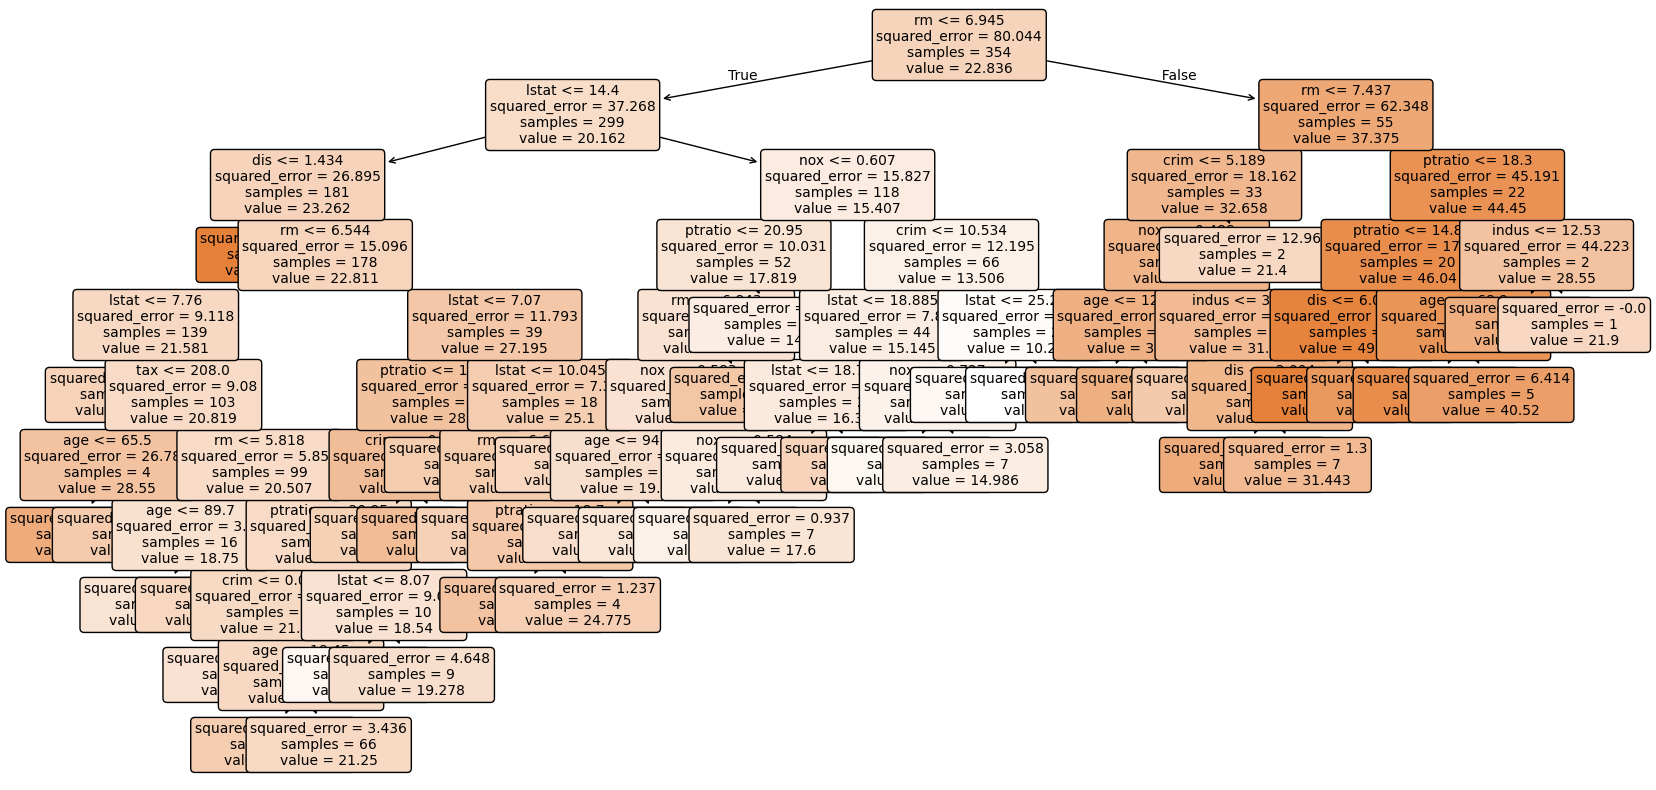

In [96]:
full_tree = DecisionTreeRegressor(random_state=2026)
alphas = full_tree.cost_complexity_pruning_path(X_train, y_train).ccp_alphas[:-1]

cv_mse, cv_se, n_leaves = [], [], []
for a in alphas:
    model = DecisionTreeRegressor(ccp_alpha=a,
                                  random_state=2026)
    mse = -cross_val_score(model,
                           X_train,
                           y_train,
                           cv=cv,
                           scoring='neg_mean_squared_error')
    cv_mse.append(mse.mean())
    cv_se.append(mse.std(ddof=1) / np.sqrt(len(mse)))
    n_leaves.append(model.fit(X_train, y_train).get_n_leaves())

cv_mse, cv_se, n_leaves = map(np.array, (cv_mse, cv_se, n_leaves))
best = cv_mse.argmin()
print(f'{len(alphas)} candidate alphas')
print(f'CV minimum: {n_leaves[best]} leaves, CV MSE {cv_mse[best]:.2f} (SE {cv_se[best]:.2f})')

fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(DecisionTreeRegressor(ccp_alpha=alphas[best],
                                  random_state=2026).fit(X_train, y_train),
          feature_names=list(X_train.columns),
          filled=True,
          rounded=True,
          fontsize=10,
          ax=ax)
plt.show()


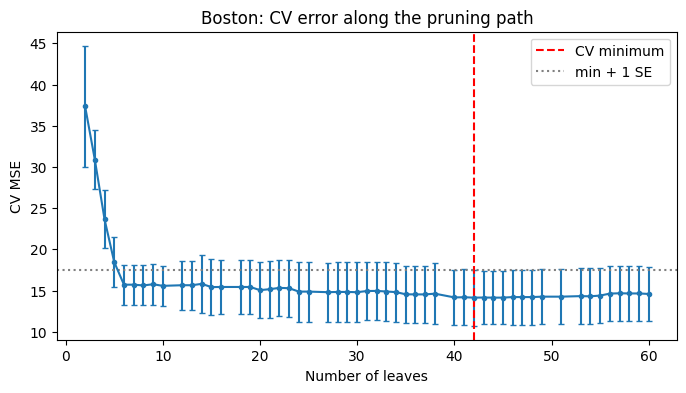

In [97]:
keep = n_leaves <= 60     # zoom in on the trees that matter

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(n_leaves[keep],
            cv_mse[keep],
            yerr=cv_se[keep],
            fmt='o-',
            ms=3,
            capsize=2)
ax.axvline(n_leaves[best],
           color='red',
           ls='--',
           label='CV minimum')
ax.axhline(cv_mse[best] + cv_se[best],
           color='grey',
           ls=':',
           label='min + 1 SE')
ax.set_xlabel('Number of leaves')
ax.set_ylabel('CV MSE')
ax.set_title('Boston: CV error along the pruning path')
ax.legend()
plt.show()




### Exercise 1.2: The one-SE tree

Apply the one-SE rule: among the candidates whose CV MSE is at most `cv_mse[best] + cv_se[best]`, choose the one with the fewest leaves. Store its index as `i_1se` and its alpha as `alpha_1se`, fit that tree on the training set as `tree_1se`, print its number of leaves and CV MSE, and plot it.

The number of leaves in this 1 standard error tree is 6 
and the CV MSE is 15.713608215880209


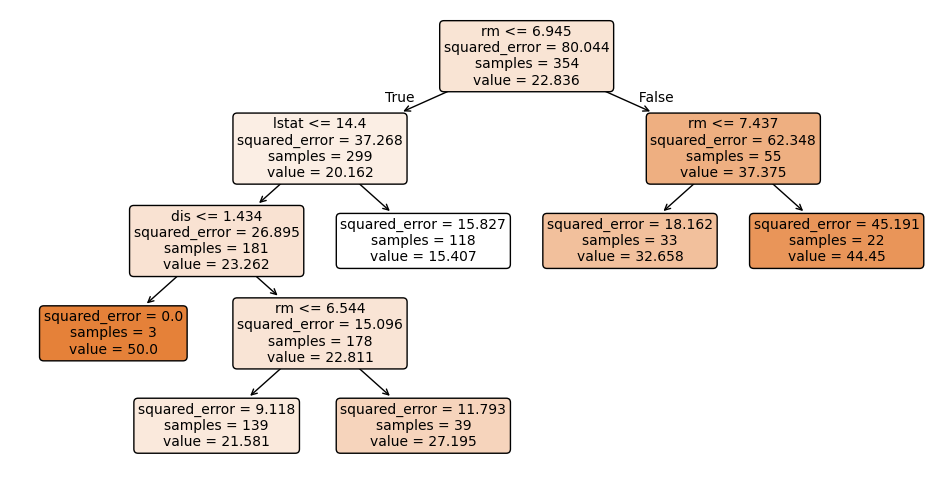

In [98]:
### YOUR CODE HERE
# 1. threshold = cv_mse[best] + cv_se[best]
# 2. Candidates: np.where(cv_mse <= threshold)[0]
# 3. Among them, the index with the fewest leaves (n_leaves[...].argmin()); call it i_1se
# 4. alpha_1se = alphas[i_1se]; fit tree_1se on the training set
# 5. Print leaves and CV MSE, then plot_tree(tree_1se, ...)

leaves_CVMSE = []

threshold = cv_mse[best] + cv_se[best]
candidates = np.where(cv_mse <= threshold)[0]
i_1se = n_leaves[candidates].argmin()
alpha_1se = alphas[i_1se]
tree_1se = DecisionTreeRegressor(ccp_alpha=alpha_1se, random_state=2026)
tree_1se.fit(X_train, y_train)

mse2 = -cross_val_score(tree_1se, X_train, y_train, cv=cv, scoring='neg_mean_squared_error')

num_leaves = tree_1se.get_n_leaves()
cv_mse2 = mse2.mean()

print(f'''The number of leaves in this 1 standard error tree is {num_leaves}
and the CV MSE is {cv_mse2}''')

# Plot the tree
fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(tree_1se,
          feature_names=list(X_train.columns),
          filled=True,
          rounded=True,
          fontsize=10,
          ax=ax)
plt.show()

In [99]:
# Identify which leaf node each training sample falls into
leaf_indices = tree_1se.apply(X_train)

# Find the leaf index that has exactly 3 samples
unique_leaves, counts = np.unique(leaf_indices, return_counts=True)
leaf_with_3_samples = unique_leaves[counts == 3][0]

# Filter the training set to get these 3 tracts
matching_tracts_X = X_train[leaf_indices == leaf_with_3_samples]
matching_tracts_y = y_train[leaf_indices == leaf_with_3_samples]

# Display their details
common_info = pd.concat([matching_tracts_X, matching_tracts_y], axis=1)
display(common_info)

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
369,4.89822,0.0,18.1,0,0.631,4.970,100.0,1.3325,24,666,20.2,3.26,50.0
372,9.23230,0.0,18.1,0,0.631,6.216,100.0,1.1691,24,666,20.2,9.53,50.0
370,5.66998,0.0,18.1,1,0.631,6.683,96.8,1.3567,24,666,20.2,3.73,50.0


❓ **Question 1.2.** Compare the CV-minimum tree with the one-SE tree in terms of the number of leaves and CV MSE. What do you give up and what do you gain by taking the one-SE tree? One leaf of the one-SE tree holds only 3 tracts. What do they have in common?

*Your answer here:*

Comparing the one-SE tree and the CV-minimum tree, the one-SE tree has higher CV MSE at (15.71> 14.14). However, in turn, the one-SE tree has less number of leave (6) compared to 42 leaves. Here, we give up some CV-MSE, that is, error, in return for less model complexity to avoid overfitting on new test-set.

The leaf of the one-SE tree that holds 3 tract all have distances less than 1.434. Moreover, after printing out the 3 observations, it can be seen that all 3 observations have a medv value of 50 which is the maximum capped house value in the dataset, and similar regional and tax profile.

***

### 1.3 Test Once, Then Refit

### Exercise 1.3: Test MSE and the final tree

1. Compute the test MSE of `tree_1se`, and its square root (RMSE).
2. Refit a tree with `ccp_alpha=alpha_1se` on **all** 506 tracts as `final_tree`, and print its number of leaves.

In [100]:
### YOUR CODE HERE
# 1. mean_squared_error(y_test, tree_1se.predict(X_test)); RMSE = its square root
# 2. final_tree = DecisionTreeRegressor(ccp_alpha=alpha_1se, random_state=2026), fit on X, y

MSE = mean_squared_error(y_test, tree_1se.predict(X_test))
RMSE = np.sqrt(MSE)
final_tree = DecisionTreeRegressor(ccp_alpha=alpha_1se, random_state=2026).fit(X, y)
print(f'The number of leaves of the final tree is {final_tree.get_n_leaves()}')
print(f'Test MSE is {MSE:.2f}, and test RMSE is {RMSE:.2f}')

The number of leaves of the final tree is 8
Test MSE is 35.01, and test RMSE is 5.92


❓ **Question 1.3.** Compare the test MSE with the one-SE tree's CV MSE. Interpret the RMSE in the units of `medv`. Which number do you report as the generalisation estimate of `final_tree`, and why is it not re-estimated after the refit?

*Your answer here:*

Despite coming from the same tree, the test MSE is higher than the CV MSE on training data, respectively 35.01 > 15.71.

The number reported in the tree regression of MEDV is currently log-transformed. In order to report as a genralization estimate, we must use the TEST MSE or test RMSE, NOT the training CV MSE.

It's not estimated after the refit because we no longer have an independent, untouched test set left to estimate generalization. If there is, let's say a new dataset, we would be able to estimate generalization.

### 1.4 Tree vs Linear Regression

The demo compares the one-SE tree with a linear regression on all 12 predictors, by 5-fold CV on the training set.

In [101]:
lin_mse = -cross_val_score(LinearRegression(),
                           X_train,
                           y_train,
                           cv=cv,
                           scoring='neg_mean_squared_error').mean()

print(f'One-SE tree CV MSE:       {cv_mse[i_1se]:.2f}')
print(f'Linear regression CV MSE: {lin_mse:.2f}')

One-SE tree CV MSE:       15.71
Linear regression CV MSE: 25.10


❓ **Question 1.4.** In the lecture, logistic regression beat the tree on Carseats. Here the tree wins clearly. Use the Part 0 scatter plots to explain why.

*Your answer here:*
Perhaps it's because the dataset fits a step function more than a linear function. It is apparent in the dataset that the relationships between rm/lstat and medv are non-linear. This contradicts linear regression who fits a perfectly straight line through, in this context, a non-linear relationship. Tree regression excels at non-linear relationship as it utilizes a step function by splitting the data-space into step regions. This step function matches the non-linear relationship better than a straight line.

***

## Part 2: Classification Trees on OJ

Each row is one purchase of orange juice: Citrus Hill (`CH`) or Minute Maid (`MM`).

Predictors include the prices and discounts of both brands, `LoyalCH` (the customer's past loyalty to Citrus Hill, between 0 and 1) and the store. The response is `MM = 1` if the customer bought Minute Maid.

`STORE` and `Store7` duplicate `StoreID`, so we drop them and dummy-encode `StoreID`. EDA is omitted here for brevity.

In [102]:
url = 'https://raw.githubusercontent.com/intro-stat-learning/ISLP/main/ISLP/data/OJ.csv'
oj = pd.read_csv(url)
oj.index = range(1, len(oj) + 1)

Xo = pd.get_dummies(oj.drop(columns=['Purchase', 'STORE', 'Store7']),
                    columns=['StoreID'],
                    drop_first=True,
                    dtype=int)
yo = (oj['Purchase'] == 'MM').astype(int)

Xo_train, Xo_test, yo_train, yo_test = train_test_split(
    Xo, yo, test_size=0.3, random_state=2026, stratify=yo)

print(f'Training: {len(Xo_train)} purchases, test: {len(Xo_test)} purchases')
print(f'Share buying MM (training): {yo_train.mean():.3f}')

Training: 749 purchases, test: 321 purchases
Share buying MM (training): 0.390


### 2.1 A One-Split Tree

Always predicting the majority class, CH, would be right for 61% of training purchases. That is the baseline any classifier must beat.

### Exercise 2.1: A stump

Fit a tree with `max_depth=1` (a single split, called a *stump*) on the training set. Plot it and report its 5-fold CV accuracy using the `cv_c` object below.

In [103]:
cv_c = StratifiedKFold(n_splits=5,
                       shuffle=True,
                       random_state=2026)

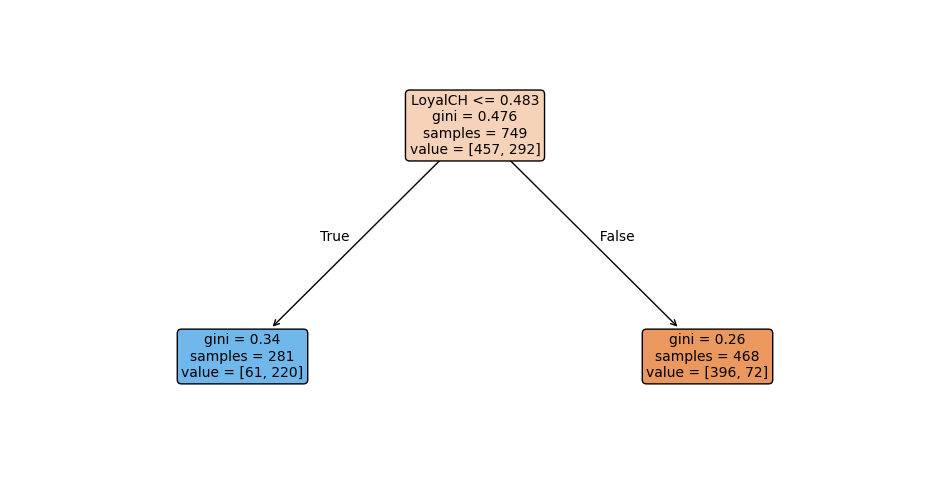

Cross-validation accuracy of Stump is 0.81


In [104]:
### YOUR CODE HERE
# 1. stump = DecisionTreeClassifier(max_depth=1, random_state=2026), fit on the training set
# 2. plot_tree(stump, feature_names=..., class_names=['CH', 'MM'], ...)
# 3. cross_val_score(stump, Xo_train, yo_train, cv=cv_c).mean()

stump = DecisionTreeClassifier(max_depth=1, random_state=2026).fit(Xo_train, yo_train)
fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(stump,
          feature_names=list(Xo_train.columns),
          filled=True,
          rounded=True,
          fontsize=10,
          ax=ax)
plt.show()

cv_accuracy = cross_val_score(stump, Xo_train, yo_train, cv=cv_c).mean()
print(f'Cross-validation accuracy of Stump is {cv_accuracy:.2f}')

❓ **Question 2.1.** Which predictor does the stump use? How much of the gap between the 61% baseline and perfect accuracy does one split close? What does that say about how customers choose orange juice?

In [105]:
print((cv_accuracy - (1-yo_train.mean())).round(5))

0.20422


*Your answer here:*

The stump uses predictor LoyalCH that ranges between 0 and 1 and leads to nodes with observations that satisfies LoyalCH smaller or equal to 0.483.

Total improvement our model could make is 1-0.61 = 0.39 if our model has perfect accuracy.

In the stump model, we achieve an accraucy of 0.81; compared to the baseline 0.61, the model improved by ~20.422%.

The model implies that brand loyalty is a strong predictor and it dominates how consumers make decisions regarding orange juice. Even with other changes such as in price or promotions, a customer with high brand loyalty towards Citrus Hill is likely to continue purchasing Citrus Hill.

### 2.2 Pruning a Classification Tree

The demo grows the full tree, computes CV accuracy along the pruning path, and applies the one-SE rule.

For accuracy, larger is better, so the threshold sits one SE *below* the best.

In [89]:
full_ctree = DecisionTreeClassifier(random_state=2026).fit(Xo_train, yo_train)
print(f'Full tree: {full_ctree.get_n_leaves()} leaves, '
      f'training accuracy {full_ctree.score(Xo_train, yo_train):.3f}')

alphas_c = full_ctree.cost_complexity_pruning_path(Xo_train, yo_train).ccp_alphas[:-1]

cv_acc, cv_se_c, leaves_c = [], [], []
for a in alphas_c:
    model = DecisionTreeClassifier(ccp_alpha=a,
                                   random_state=2026)
    acc = cross_val_score(model,
                          Xo_train,
                          yo_train,
                          cv=cv_c)
    cv_acc.append(acc.mean())
    cv_se_c.append(acc.std(ddof=1) / np.sqrt(len(acc)))
    leaves_c.append(model.fit(Xo_train, yo_train).get_n_leaves())

cv_acc, cv_se_c, leaves_c = map(np.array, (cv_acc, cv_se_c, leaves_c))
best_c = cv_acc.argmax()
within_c = np.where(cv_acc >= cv_acc[best_c] - cv_se_c[best_c])[0]
i_c = within_c[leaves_c[within_c].argmin()]
alpha_c = alphas_c[i_c]

print(f'Best CV accuracy: {cv_acc[best_c]:.3f} ({leaves_c[best_c]} leaves)')
print(f'One-SE tree:      {cv_acc[i_c]:.3f} ({leaves_c[i_c]} leaves)')

Full tree: 148 leaves, training accuracy 0.991
Best CV accuracy: 0.824 (11 leaves)
One-SE tree:      0.824 (6 leaves)


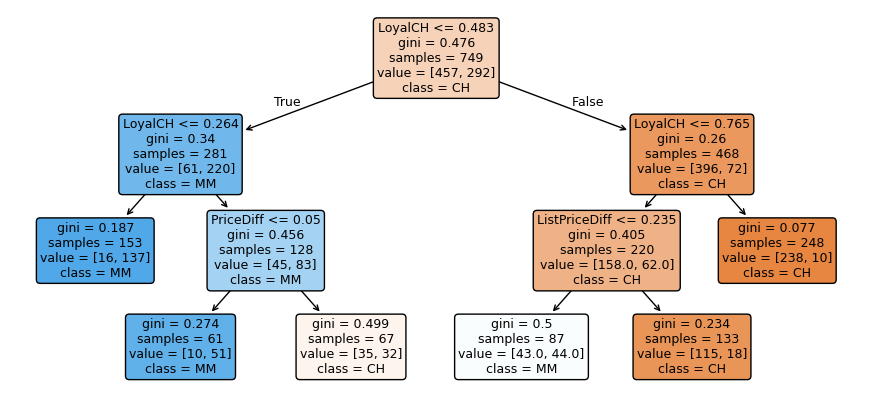

In [106]:
ctree = DecisionTreeClassifier(ccp_alpha=alpha_c,
                               random_state=2026)
ctree.fit(Xo_train, yo_train);

fig, ax = plt.subplots(figsize=(11, 5))
plot_tree(ctree,
          feature_names=list(Xo_train.columns),
          class_names=['CH', 'MM'],
          filled=True,
          rounded=True,
          fontsize=9,
          ax=ax)
plt.show()

❓ **Question 2.2.** Read the pruned tree. `LoyalCH` is split on several times. Describe in words how a customer's loyalty and the price difference between the brands drive the prediction. Two leaves have class counts close to 50/50. Find them. What does their predicted class really mean?

*Your answer here:*

Customer loyalty and price difference are used to compare between Citrus Hill and MinuteMaid to predict whether a new observation, given customer loyalty and price difference, will be classified to either brand. The process follows:
1. The customer's loyalty towards Citrus Hill is analyzed first; if it's high (above 0.483), the customer is predicted to purchase CH immediately, if not, they purchase MinuteMaid.
2. Within the sample people with loyalty to CH less than 0.483, some would choose MinuteMaid immediately, some would choose CH depending on prices.
3. In the leaves, some customers, who are disloyal to CH, would purchase CH if price differences are less than 0.05.

Leaves that have class count close to 50/50 (gini) are the two leaves in the middle, respectively with 67, and 87 samples. Their predicted class means that, the probability choosing MinuteMaid or Citrus Hill is like a coin toss - the classification is almost at maximum uncertainty, the most impure. Consequently, loyalty level and price differences do not provide enough statistical evidence to predict which brand these observations/customers will purchase.

***

### 2.3 Test Once

### Exercise 2.3: Test-set evaluation

Evaluate `ctree` once on the test set:

1. Test accuracy and the confusion matrix (rows: true CH, MM; columns: predicted CH, MM).
2. Sensitivity for MM: the share of true MM purchases predicted MM.
3. The number of distinct values in `ctree.predict_proba(Xo_test)[:, 1]`.

In [137]:
### YOUR CODE HERE
# 1. pred = ctree.predict(Xo_test); accuracy_score(...), confusion_matrix(...)
# 2. sensitivity = true MM predicted MM / all true MM
# 3. np.unique(ctree.predict_proba(Xo_test)[:, 1]).size

pred = ctree.predict(Xo_test)
accuracy = accuracy_score(yo_test, pred, normalize=False, sample_weight=None)
cm = confusion_matrix(yo_test, pred, normalize=None, sample_weight=None)

true_positive_mm = np.sum((yo_test == 1) & (pred == 1))
all_positive_mm = np.sum(yo_test==1)
sensitivity_mm = (true_positive)/(all_positive)

true_positive_ch = np.sum((yo_test == 0) & (pred == 0))
all_positive_ch = np.sum(yo_test==0)
sensitivity_ch = (true_positive_ch)/(all_positive_ch)

distinct_value = np.unique(ctree.predict_proba(Xo_test)[:, 1]).size
print(sensitivity_mm, sensitivity_ch.round(3))
print(distinct_value)

0.696 0.827
6


❓ **Question 2.3.** Is the tree better at recognising CH buyers or MM buyers? If a marketing team wanted to catch more MM buyers, they would lower the probability threshold for predicting MM. Why does the number of distinct probabilities limit how finely they can do this?

*Your answer here:*

It appears that the tree is better at recognizing CH buyers than MM buyers in terms of their sensitivity (0.827 > 0.696).

The number of distinct probabilities limit how finely the marketing team can lower the probability threshold because even if they lower, there's a chance where the shifting threshold slightly does nothing until the leaves value crosses its specific condition.

This is why Tree Regression are hard to fine tune as slightly changing threshold may not change the outcome at all.


### 2.4 Tree vs Logistic Regression

The demo compares the stump, the pruned tree and logistic regression by CV accuracy on the training set.

In [138]:
logit = make_pipeline(StandardScaler(),
                      LogisticRegression())

pd.Series({
    'Stump (1 split)':     cross_val_score(stump, Xo_train, yo_train, cv=cv_c).mean(),
    'Pruned tree':         cv_acc[i_c],
    'Logistic regression': cross_val_score(logit, Xo_train, yo_train, cv=cv_c).mean(),
}).round(3)

,0
Stump (1 split),0.814
Pruned tree,0.824
Logistic regression,0.842


❓ **Question 2.4.** A store manager wants a rule her staff can apply at the shelf. Which model would you give her? What would she lose compared with the most accurate model? Would your answer change if the model ran inside a recommendation system?

*Your answer here:*
I would provide her the Stump model because it's the most intuitive to view and the least complex. Compared to the most accurate model which is logistic regression, she loses on predictive accuracy, but gains in speed and efficiency.

In a recommendation system where insights of customers can be known, I believe that a pruned tree should be apply because a recommendation system would be ran by a computer, faster in computation than a human. Hence,  a pruned model is suitable once consumer data is known, the pruned tree and its predictions can be automated with a computer.

***

## Lab Checklist

Before submitting, confirm you have:

- [ ] Run all demo cells without errors
- [ ] Answered Question 1.1a
- [ ] Completed Exercise 1.1 (training vs CV error) and answered Question 1.1b
- [ ] Completed Exercise 1.2 (the one-SE tree) and answered Question 1.2
- [ ] Completed Exercise 1.3 (test MSE and the final tree) and answered Question 1.3
- [ ] Answered Question 1.4
- [ ] Completed Exercise 2.1 (a stump) and answered Question 2.1
- [ ] Answered Question 2.2
- [ ] Completed Exercise 2.3 (test-set evaluation) and answered Question 2.3
- [ ] Answered Question 2.4